# 📉 Customer Churn Prediction using Data Mining
Predicting which telecom customers are likely to **leave the company (churn)** using **Logistic Regression** on the Telco Customer Churn dataset (7,043 customers, 21 columns).

**Pipeline:** Setup → EDA → Preprocessing → Modeling & Evaluation

*Authors: Maria Jaber · Aseel Hassan · Aseel Alshishani · Hala AlJafary*

## 1. Setup

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split

In [2]:
DATA_PATH = "Telco_Customer_Churn.csv"  # path to the dataset CSV
TEST_SIZE = 0.2
RANDOM_STATE = 42

## 2. Exploratory Data Analysis (EDA)

### 2.1 Data overview

In [3]:
df = pd.read_csv(DATA_PATH)

In [4]:
df.head()

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No     1.0           No   
1  5575-GNVDE    Male              0      No         No    34.0          Yes   
2  3668-QPYBK    Male              0      No         No     2.0          Yes   
3  7795-CFOCW    Male              0      No         No    45.0           No   
4  9237-HQITU  Female              0      No         No     2.0          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [5]:
df.tail()

      customerID  gender  SeniorCitizen Partner Dependents  tenure  \
7038  6840-RESVB    Male              0     Yes        Yes    24.0   
7039  2234-XADUH  Female              0     Yes        Yes    72.0   
7040  4801-JZAZL  Female              0     Yes        Yes    11.0   
7041  8361-LTMKD    Male              1     Yes         No     4.0   
7042  3186-AJIEK    Male              0      No         No    66.0   

     PhoneService     MultipleLines InternetService OnlineSecurity  ...  \
7038          Yes               Yes             DSL            Yes  ...   
7039          Yes               Yes     Fiber optic             No  ...   
7040           No  No phone service             DSL            Yes  ...   
7041          Yes               Yes     Fiber optic             No  ...   
7042          Yes                No     Fiber optic            Yes  ...   

     DeviceProtection TechSupport StreamingTV StreamingMovies        Contract  \
7038              Yes         Yes         Yes  

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            6973 non-null   float64
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [7]:
df.shape

(7043, 21)

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.000,1.00
tenure,6973.0,32.425785,24.560791,0.00,9.0,29.00,56.000,72.00
MonthlyCharges,7043.0,65.005111,31.651740,18.25,35.5,70.35,89.875,519.25


In [9]:
df.describe(include='object').T

,count,unique,top,freq
customerID,7043,7043,3186-AJIEK,1
gender,7043,2,Male,3555
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,4,Fiber optic,3046
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095


In [10]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,70
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [11]:
df.duplicated().sum()

np.int64(0)

### 2.2 Visualizations

In [12]:
corr = df.corr(numeric_only=True)
corr

,SeniorCitizen,tenure,MonthlyCharges
SeniorCitizen,1.000000,0.015134,0.214568
tenure,0.015134,1.000000,0.229696
MonthlyCharges,0.214568,0.229696,1.000000


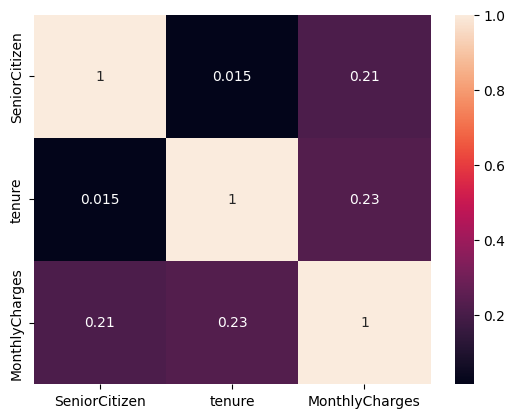

In [13]:
sns.heatmap(corr, annot=True)
plt.show()

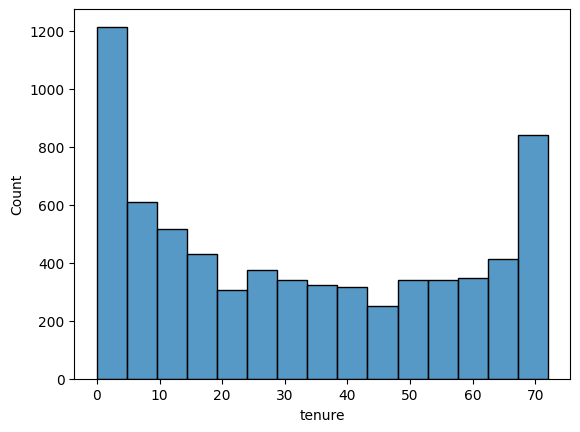

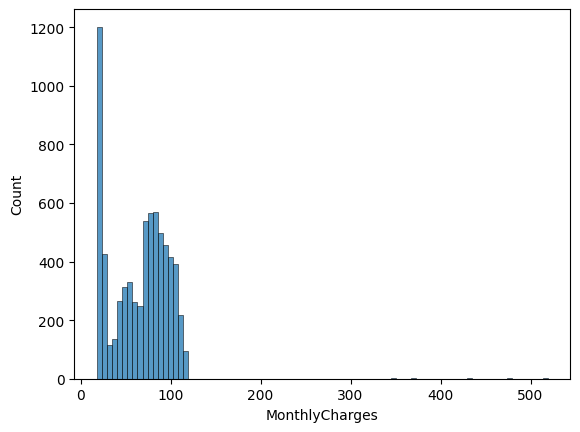

In [14]:
for col in ['tenure', 'MonthlyCharges']:
    sns.histplot(data=df, x=col)
    plt.show()

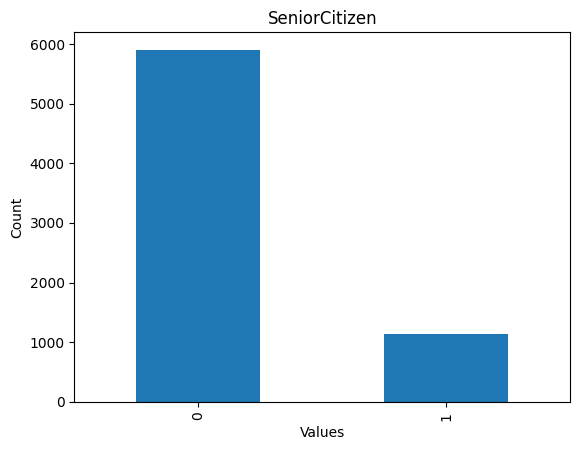

In [15]:
df['SeniorCitizen'].value_counts().plot(kind='bar')
plt.xlabel('Values')
plt.ylabel('Count')
plt.title('SeniorCitizen')
plt.show()

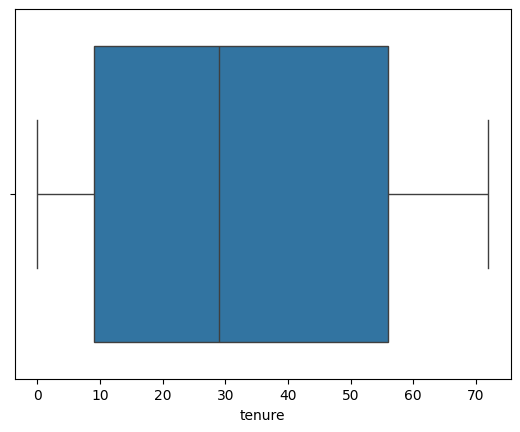

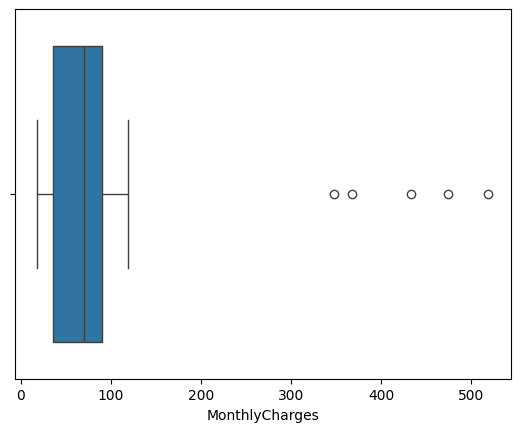

In [16]:
for col in ['tenure', 'MonthlyCharges']:
    sns.boxplot(data=df, x=col)
    plt.show()

## 3. Preprocessing

### 3.1 Remove unnecessary columns

In [17]:
df = df.drop(columns='customerID')

### 3.2 Fix data type mismatch
`TotalCharges` is stored as text (object), so it is converted to float. Values that cannot be converted become `NaN`.

In [18]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            6973 non-null   float64
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


In [20]:
df['TotalCharges'].isnull().sum()

np.int64(11)

The missing `TotalCharges` values are filled with the **median** (the column is right-skewed).

In [21]:
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

In [22]:
df['TotalCharges'].isnull().sum()

np.int64(0)

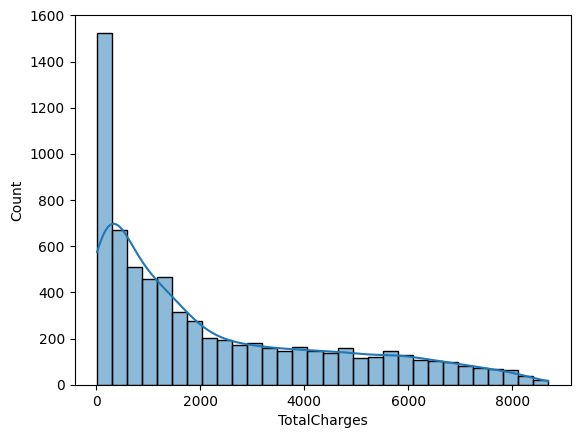

In [23]:
sns.histplot(data=df, x='TotalCharges', kde=True, bins=30)
plt.show()

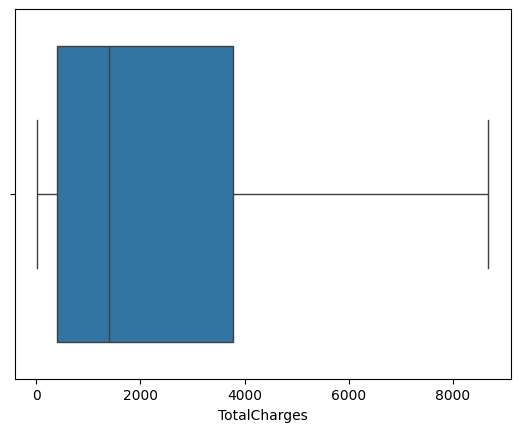

In [24]:
sns.boxplot(data=df, x='TotalCharges')
plt.show()

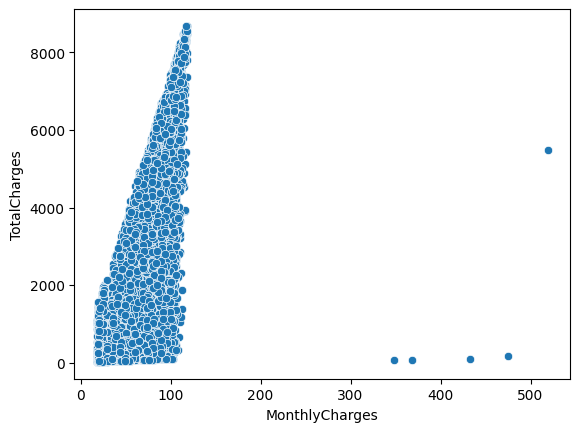

In [25]:
sns.scatterplot(data=df, x='MonthlyCharges', y='TotalCharges')
plt.show()

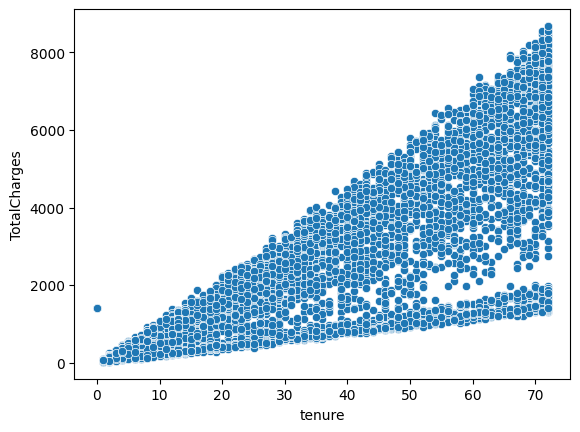

In [26]:
sns.scatterplot(data=df, x='tenure', y='TotalCharges')
plt.show()

In [27]:
corr = df[['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']].corr(numeric_only=True)

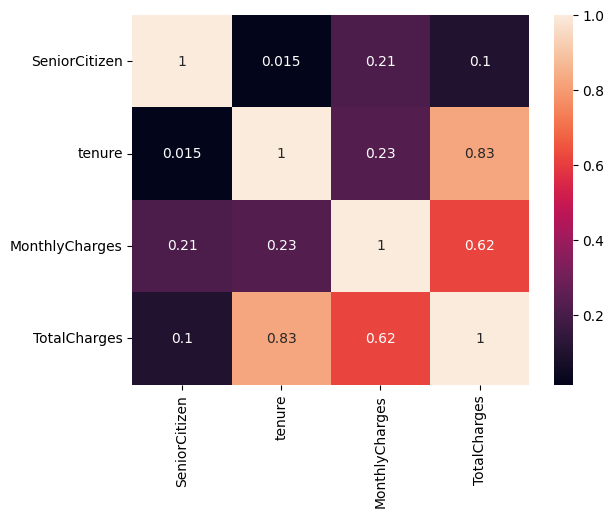

In [28]:
sns.heatmap(corr, annot=True)
plt.show()

### 3.3 Missing values
Missing `tenure` values are filled with the **median**.

In [29]:
df['tenure'].isnull().sum()

np.int64(70)

In [30]:
df['tenure'] = df['tenure'].fillna(df['tenure'].median())

In [31]:
df['tenure'].isnull().sum()

np.int64(0)

### 3.4 Unknown class
`InternetService` contains an invalid `Unknown` class, which is replaced with the most frequent value (mode).

In [32]:
df['InternetService'].value_counts()

,count
InternetService,
Fiber optic,3046
DSL,2387
No,1505
Unknown,105


In [33]:
mode = df['InternetService'].mode()[0]
df['InternetService'] = df['InternetService'].replace('Unknown', mode)

In [34]:
df['InternetService'].value_counts()

,count
InternetService,
Fiber optic,3151
DSL,2387
No,1505


### 3.5 Label encoding and one-hot encoding
- Binary `Yes/No` columns → `1/0`
- Remaining categorical columns → one-hot encoding

In [35]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1.0,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34.0,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2.0,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45.0,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2.0,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [36]:
for col in df.select_dtypes('object').columns:
    print(df[col].value_counts())
    print('___________________')

gender
Male      3555
Female    3488
Name: count, dtype: int64
___________________
Partner
No     3641
Yes    3402
Name: count, dtype: int64
___________________
Dependents
No     4933
Yes    2110
Name: count, dtype: int64
___________________
PhoneService
Yes    6361
No      682
Name: count, dtype: int64
___________________
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64
___________________
InternetService
Fiber optic    3151
DSL            2387
No             1505
Name: count, dtype: int64
___________________
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64
___________________
OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64
___________________
DeviceProtection
No                     3095
Yes                    2422
No internet service    1526
Name: count, dtype: int64
___

In [37]:
binary_columns_yes_no = ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'Churn']
for col in binary_columns_yes_no:
    df[col] = df[col].map({'Yes': 1, 'No': 0})

In [38]:
categorical_cols = df.select_dtypes(exclude='number').columns
df = pd.get_dummies(df, columns=categorical_cols, dtype='int')

Check that no text (object) columns are left:

In [39]:
df.select_dtypes(exclude='number').columns

Index([], dtype='object')

In [40]:
df.head()

   SeniorCitizen  Partner  Dependents  tenure  PhoneService  PaperlessBilling  \
0              0        1           0     1.0             0                 1   
1              0        0           0    34.0             1                 0   
2              0        0           0     2.0             1                 1   
3              0        0           0    45.0             0                 0   
4              0        0           0     2.0             1                 1   

   MonthlyCharges  TotalCharges  Churn  gender_Female  ...  \
0           29.85         29.85      0              1  ...   
1           56.95       1889.50      0              0  ...   
2           53.85        108.15      1              0  ...   
3           42.30       1840.75      0              0  ...   
4           70.70        151.65      1              1  ...   

   StreamingMovies_No  StreamingMovies_No internet service  \
0                   1                                    0   
1               

In [41]:
df.shape

(7043, 42)

In [42]:
df.columns

Index(['SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService',
       'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'Churn',
       'gender_Female', 'gender_Male', 'MultipleLines_No',
       'MultipleLines_No phone service', 'MultipleLines_Yes',
       'InternetService_DSL', 'InternetService_Fiber optic',
       'InternetService_No', 'OnlineSecurity_No',
       'OnlineSecurity_No internet service', 'OnlineSecurity_Yes',
       'OnlineBackup_No', 'OnlineBackup_No internet service',
       'OnlineBackup_Yes', 'DeviceProtection_No',
       'DeviceProtection_No internet service', 'DeviceProtection_Yes',
       'TechSupport_No', 'TechSupport_No internet service', 'TechSupport_Yes',
       'StreamingTV_No', 'StreamingTV_No internet service', 'StreamingTV_Yes',
       'StreamingMovies_No', 'StreamingMovies_No internet service',
       'StreamingMovies_Yes', 'Contract_Month-to-month', 'Contract_One year',
       'Contract_Two year', 'PaymentMethod_Bank transfer (automatic)'

## 4. Modeling — Logistic Regression

### 4.1 Train / test split (80% / 20%)

In [43]:
x = df.drop(columns=['Churn'])
y = df['Churn']
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)
X_train.shape, X_test.shape

((5634, 41), (1409, 41))

### 4.2 Train the model

In [44]:
model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


### 4.3 Evaluation

In [45]:
confusion_matrix(y_test, y_pred)

array([[938,  98],
       [162, 211]])

In [46]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Accuracy: 0.815471965933286
Precision: 0.6828478964401294
Recall: 0.5656836461126006
F1 Score: 0.6187683284457478
